# Chapitre 5 - Cours 1 : polynômes par morceaux, splines et B-splines

Ce premier notebook du chapitre 5 (*Basis Expansions and Regularization*) présente
l'idée centrale du chapitre : **remplacer la variable d'entrée $X$ par des
transformations $h_1(X), \dots, h_M(X)$** puis ajuster un modèle *linéaire* dans ces
nouvelles variables. Nous verrons :

1. les expansions en bases de fonctions (§5.1) ;
2. les polynômes par morceaux et les splines (§5.2, figures 5.1 et 5.2) ;
3. la base des B-splines et la récurrence de Cox-de Boor (annexe du chapitre, figure 5.20) ;
4. les splines cubiques naturelles et la variance ponctuelle (§5.2.1, figure 5.3) ;
5. l'exemple de la reconnaissance de phonèmes : filtrer les entrées par une base de
   splines (§5.2.3 et §5.3, figure 5.5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (piecewise_polynomial_basis, truncated_power_basis,
                              bspline_basis, natural_spline_basis, logistic_irls)
set_style()

## 1. Expansions en bases de fonctions

Les modèles linéaires des chapitres 3 et 4 supposent que la fonction de régression
$f(X) = \mathbb E(Y \mid X)$ est linéaire en $X$. C'est rarement vrai, mais c'est une
approximation commode. Pour aller au-delà **sans abandonner les outils linéaires**, on
se donne des fonctions $h_m : \mathbb R^p \to \mathbb R$, $m = 1, \dots, M$, et l'on pose
(éq. (5.1) du livre)

$$
f(X) = \sum_{m=1}^{M} \beta_m\, h_m(X).
$$

Le modèle est **linéaire en les paramètres** $\beta_m$ : une fois les $h_m$ choisies,
l'ajustement par moindres carrés est exactement celui du chapitre 3, avec la matrice de
régression $\mathbf H = (h_m(x_i))_{i,m}$ de taille $N \times M$ :
$\hat\beta = (\mathbf H^T \mathbf H)^{-1}\mathbf H^T \mathbf y$.

Exemples de choix de $h_m$ :

- $h_m(X) = X_m$ : on retrouve le modèle linéaire ;
- $h_m(X) = X_j^2$ ou $X_j X_k$ : polynôme de degré 2 (le nombre de termes explose avec $p$) ;
- $h_m(X) = \log X_j$, $\sqrt{X_j}$ : transformations non linéaires d'une seule variable ;
- $h_m(X) = \mathbf 1(L_m \le X_k < U_m)$ : indicatrices d'intervalles, qui donnent des
  fonctions constantes par morceaux.

> **Intuition.** Un polynôme global est trop rigide : modifier les données à un endroit
> modifie l'ajustement partout. Les polynômes **par morceaux** et les splines sont
> *locaux*, ce qui les rend beaucoup plus souples.

Jusqu'au §5.7, $X$ est **unidimensionnel**.

## 2. Polynômes par morceaux

On découpe le domaine de $X$ en intervalles contigus délimités par des **nœuds**
$\xi_1 < \xi_2 < \dots < \xi_K$, et l'on représente $f$ par un polynôme différent sur
chaque intervalle. Nous utilisons des données simulées, avec deux nœuds
$\xi_1 = 1/3$ et $\xi_2 = 2/3$, pour reproduire l'esprit des figures 5.1 et 5.2.

In [2]:
rng = np.random.RandomState(0)
N = 60
x = np.sort(rng.uniform(0, 1, N))
f_true = lambda t: np.sin(2.5 * np.pi * t) * np.exp(-t) + 0.5 * t
y = f_true(x) + 0.25 * rng.randn(N)
knots = np.array([1 / 3, 2 / 3])
grid = np.linspace(0, 1, 400)

### Constante par morceaux

Avec trois fonctions de base
$h_1(X) = \mathbf 1(X < \xi_1)$, $h_2(X) = \mathbf 1(\xi_1 \le X < \xi_2)$,
$h_3(X) = \mathbf 1(\xi_2 \le X)$, les colonnes de $\mathbf H$ ont des supports disjoints,
donc $\mathbf H^T\mathbf H = \mathrm{diag}(N_1, N_2, N_3)$ où $N_m$ est le nombre
d'observations dans la région $m$, et $(\mathbf H^T \mathbf y)_m = \sum_{x_i \in R_m} y_i$.
Ainsi

$$
\hat\beta_m = \frac{1}{N_m}\sum_{x_i \in R_m} y_i = \bar y_m ,
$$

la **moyenne des $y_i$ dans la région $m$**.

In [3]:
def fit_predict(Hfun, x, y, grid):
    """Moindres carrés dans la base Hfun ; retourne l'ajustement sur la grille."""
    H = Hfun(x)
    beta, *_ = np.linalg.lstsq(H, y, rcond=None)
    return Hfun(grid) @ beta, beta

H0 = lambda t: np.column_stack([t < knots[0], (t >= knots[0]) & (t < knots[1]),
                                t >= knots[1]]).astype(float)
_, beta0 = fit_predict(H0, x, y, grid)
moyennes = [y[x < knots[0]].mean(), y[(x >= knots[0]) & (x < knots[1])].mean(),
            y[x >= knots[1]].mean()]
print("coefficients :", np.round(beta0, 4))
print("moyennes     :", np.round(moyennes, 4))

coefficients : [ 0.5832 -0.0866  0.5596]
moyennes     : [ 0.5832 -0.0866  0.5596]


### Linéaire par morceaux, puis continue

Pour un ajustement linéaire par morceaux, on ajoute $h_{m+3}(X) = h_m(X)\,X$ : six
paramètres. En général on préfère une fonction **continue** aux nœuds. La continuité en
$\xi_1$, $f(\xi_1^-) = f(\xi_1^+)$, s'écrit $\beta_1 + \xi_1\beta_4 = \beta_2 + \xi_1\beta_5$ :
c'est une **contrainte linéaire**. Deux nœuds donnent deux contraintes, d'où
$6 - 2 = 4$ paramètres libres.

Une base qui incorpore directement les contraintes est

$$
h_1(X) = 1,\quad h_2(X) = X,\quad h_3(X) = (X - \xi_1)_+,\quad h_4(X) = (X-\xi_2)_+,
$$

où $t_+ = \max(t, 0)$ désigne la partie positive. Chaque $h_m$ est continue et affine
par morceaux ; toute combinaison l'est donc aussi. Réciproquement, une fonction affine par
morceaux continue se décrit par la pente et l'ordonnée du premier morceau, puis par les
**changements de pente** en $\xi_1$ et $\xi_2$ : exactement 4 nombres.

In [4]:
H1 = lambda t: piecewise_polynomial_basis(t, knots, degree=1, continuity=-1)
H1c = lambda t: piecewise_polynomial_basis(t, knots, degree=1, continuity=0)
fits = {
    "Constante par morceaux": fit_predict(H0, x, y, grid)[0],
    "Linéaire par morceaux": fit_predict(H1, x, y, grid)[0],
    "Linéaire par morceaux continue": fit_predict(H1c, x, y, grid)[0],
}

La figure suivante reproduit la figure 5.1 du livre : les trois ajustements, puis (en bas
à droite) la fonction de base $(X - \xi_1)_+$.

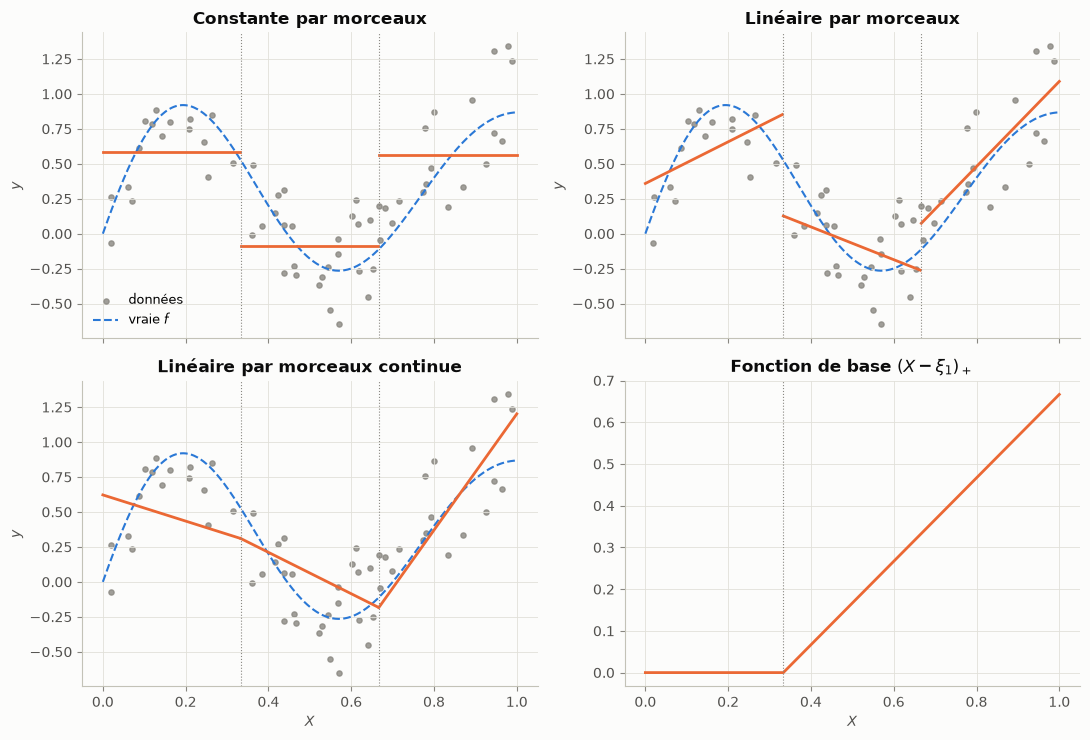

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, (titre, fit) in zip(axes.ravel()[:3], fits.items()):
    ax.scatter(x, y, s=14, color=GRAY, alpha=0.8, label="données")
    ax.plot(grid, f_true(grid), color=BLUE, lw=1.5, ls="--", label="vraie $f$")
    for g in np.split(np.arange(len(grid)), np.searchsorted(grid, knots)):
        ax.plot(grid[g], fit[g], color=ORANGE)
    ax.set_title(titre)
    ax.set_ylabel("$y$")
    for k in knots:
        ax.axvline(k, color=GRAY, lw=0.8, ls=":")
ax = axes[1, 1]
ax.plot(grid, np.maximum(grid - knots[0], 0), color=ORANGE)
ax.axvline(knots[0], color=GRAY, lw=0.8, ls=":")
ax.set_title(r"Fonction de base $(X-\xi_1)_+$")
axes[0, 0].legend(loc="lower left")
for ax in axes[1]:
    ax.set_xlabel("$X$")
plt.tight_layout()
plt.show()

### Polynômes cubiques par morceaux et ordres de continuité (figure 5.2)

Passons à des cubiques par morceaux. Sur chacune des $K + 1 = 3$ régions, un polynôme
de degré 3 a 4 coefficients : $3 \times 4 = 12$ paramètres. Imposer la continuité des
dérivées d'ordre $0, 1, \dots, c$ en chaque nœud ajoute $c + 1$ contraintes par nœud.

Une base commode s'obtient avec les **puissances tronquées** : on prend
$1, X, X^2, X^3$ puis, pour chaque nœud, $(X - \xi_k)_+^j$ pour $j = c+1, \dots, 3$
(avec la convention $(X-\xi)_+^0 = \mathbf 1(X \ge \xi)$). En effet $(X-\xi)_+^j$ a des
dérivées continues jusqu'à l'ordre $j-1$ en $\xi$, et sa dérivée $j$-ième saute de $j!$.
La dimension vaut donc

$$
4 + K\,(3 - c) \;=\; 3\times 4 - K\,(c+1)\quad\text{pour } K = 2 .
$$

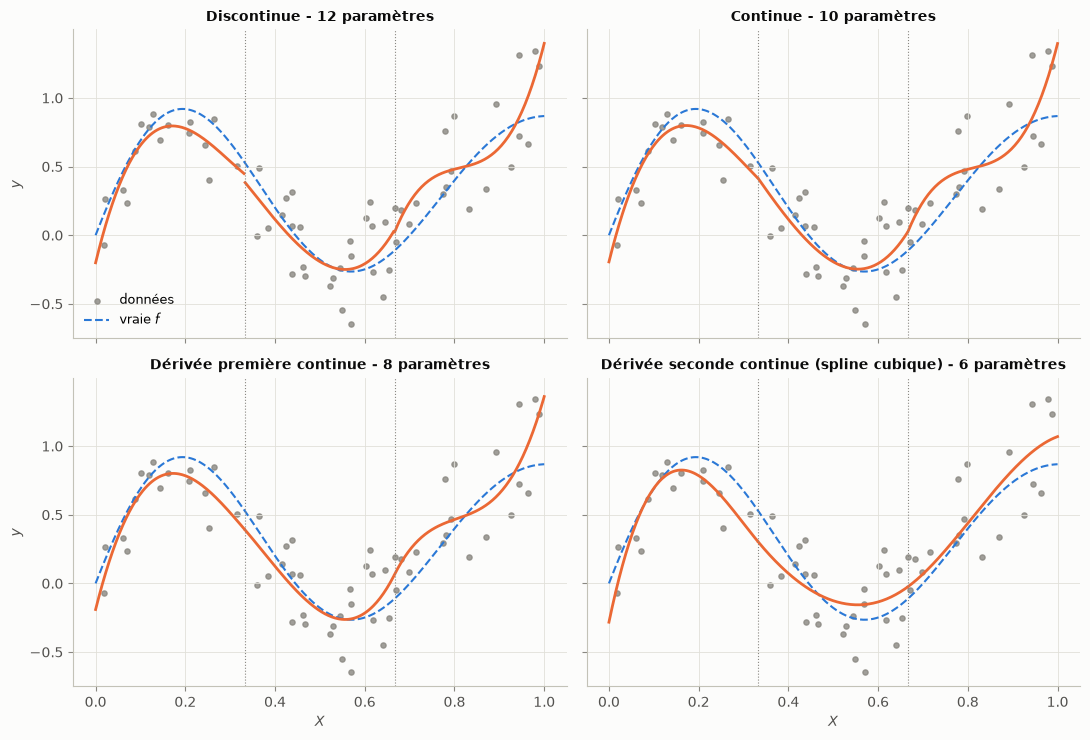

In [6]:
titres = {-1: "Discontinue", 0: "Continue", 1: "Dérivée première continue",
          2: "Dérivée seconde continue (spline cubique)"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), [-1, 0, 1, 2]):
    Hc = lambda t, c=c: piecewise_polynomial_basis(t, knots, degree=3, continuity=c)
    fit, beta = fit_predict(Hc, x, y, grid)
    ax.scatter(x, y, s=14, color=GRAY, alpha=0.8, label="données")
    ax.plot(grid, f_true(grid), color=BLUE, lw=1.5, ls="--", label="vraie $f$")
    for g in np.split(np.arange(len(grid)), np.searchsorted(grid, knots)):
        ax.plot(grid[g], fit[g], color=ORANGE)
    for k in knots:
        ax.axvline(k, color=GRAY, lw=0.8, ls=":")
    ax.set_title("%s - %d paramètres" % (titres[c], len(beta)), fontsize=10)
axes[0, 0].legend(loc="lower left")
for ax in axes[1]:
    ax.set_xlabel("$X$")
for ax in axes[:, 0]:
    ax.set_ylabel("$y$")
plt.tight_layout()
plt.show()

## 3. Splines et base des puissances tronquées

La fonction en bas à droite - continue ainsi que ses dérivées première et seconde - est
une **spline cubique**. Une contrainte de plus (dérivée troisième continue) forcerait un
polynôme cubique global. Avec deux nœuds, la base (éq. (5.3) du livre)

$$
h_1 = 1,\; h_2 = X,\; h_3 = X^2,\; h_4 = X^3,\; h_5 = (X-\xi_1)_+^3,\; h_6 = (X - \xi_2)_+^3
$$

engendre l'espace des splines cubiques (exercice 5.1) : on vérifie le compte
$3 \times 4 - 2 \times 3 = 6$.

**Définition.** Une **spline d'ordre $M$** de nœuds $\xi_1, \dots, \xi_K$ est un polynôme
par morceaux de degré $M - 1$ dont les dérivées sont continues jusqu'à l'ordre $M - 2$.
Sa base des puissances tronquées est
$h_j(X) = X^{j-1}$ ($j = 1, \dots, M$) et $h_{M+\ell}(X) = (X - \xi_\ell)_+^{M-1}$
($\ell = 1, \dots, K$) : dimension $M + K$. Les ordres usuels sont $M = 1, 2$ et $4$
(splines constantes, linéaires continues, cubiques).

Vérifions numériquement sur la spline cubique ajustée que seules les **dérivées
troisièmes** sautent aux nœuds, et que le saut en $\xi_k$ vaut $3!\,\hat\beta_{4+k}$.

In [7]:
Hs = lambda t: truncated_power_basis(t, knots, degree=3)
_, beta_s = fit_predict(Hs, x, y, grid)

def derivee_spline(t, beta, ordre):
    """Dérivée d'ordre 'ordre' de la spline (base des puissances tronquées), calcul exact."""
    from math import factorial
    out = np.zeros_like(t)
    for j in range(4):
        if j >= ordre:
            out += beta[j] * factorial(j) / factorial(j - ordre) * t ** (j - ordre)
    for k, xi in enumerate(knots):
        if ordre <= 3:
            coef = factorial(3) / factorial(3 - ordre)
            out += beta[4 + k] * coef * np.where(t > xi, (t - xi) ** (3 - ordre), 0.0)
    return out

eps = 1e-9
for ordre in range(4):
    sauts = [derivee_spline(np.array([xi + eps]), beta_s, ordre)[0]
             - derivee_spline(np.array([xi - eps]), beta_s, ordre)[0] for xi in knots]
    print("dérivée d'ordre %d : sauts aux nœuds = %s" % (ordre, np.round(sauts, 6)))
print("6 * beta_5, 6 * beta_6 =", np.round(6 * beta_s[4:], 6))

dérivée d'ordre 0 : sauts aux nœuds = [-0.  0.]
dérivée d'ordre 1 : sauts aux nœuds = [0. 0.]
dérivée d'ordre 2 : sauts aux nœuds = [ 0. -0.]
dérivée d'ordre 3 : sauts aux nœuds = [-421.185827 -181.781195]
6 * beta_5, 6 * beta_6 = [-421.185827 -181.781195]


> **Remarque (splines de régression).** Ces splines à nœuds fixés s'appellent
> **splines de régression**. Il faut choisir l'ordre, le nombre de nœuds et leur
> position ; une pratique courante est de fixer le nombre de degrés de liberté et de
> placer les nœuds aux quantiles des $x_i$ (comme `bs(x, df=7)` en R).

## 4. La base des B-splines

La base des puissances tronquées est simple mais **numériquement mauvaise** : les
fonctions $(X - \xi_k)_+^3$ sont presque colinéaires et prennent de grandes valeurs. La
base des **B-splines** (annexe du chapitre) engendre le même espace avec des fonctions
positives à **support local**.

**Suite de nœuds augmentée.** On ajoute deux nœuds de bord $\xi_0 < \xi_1$ et
$\xi_K < \xi_{K+1}$ et l'on définit $\tau_1 \le \dots \le \tau_{K+2M}$ par
$\tau_1 = \dots = \tau_M = \xi_0$, $\tau_{M+j} = \xi_j$ ($j = 1..K$),
$\tau_{K+M+1} = \dots = \tau_{K+2M} = \xi_{K+1}$.

**Récurrence de Cox-de Boor** (éq. (5.77)-(5.78) du livre) :

$$
B_{i,1}(x) = \mathbf 1(\tau_i \le x < \tau_{i+1}), \qquad
B_{i,m}(x) = \frac{x - \tau_i}{\tau_{i+m-1} - \tau_i}\,B_{i,m-1}(x)
           + \frac{\tau_{i+m} - x}{\tau_{i+m} - \tau_{i+1}}\,B_{i+1,m-1}(x),
$$

avec la convention « $0/0 = 0$ » quand des nœuds sont répétés. Les $K + M$ fonctions
$B_{i,M}$ forment une base des splines d'ordre $M$ sur $[\xi_0, \xi_{K+1}]$.

Propriétés (démontrées à l'exercice 5.2) :

- $B_{i,M}$ est nulle hors de $[\tau_i, \tau_{i+M}]$ : **support de $M+1$ nœuds** ;
- $B_{i,M} > 0$ à l'intérieur de son support ;
- $\sum_i B_{i,M}(x) = 1$ : **partition de l'unité** ;
- $B_{i,M}$ est un polynôme par morceaux de degré $M-1$, à cassures aux nœuds.

La figure suivante reproduit la figure 5.20 : B-splines d'ordres 1 à 4 avec des nœuds
régulièrement espacés de 0 à 1 (pas de 0,1).

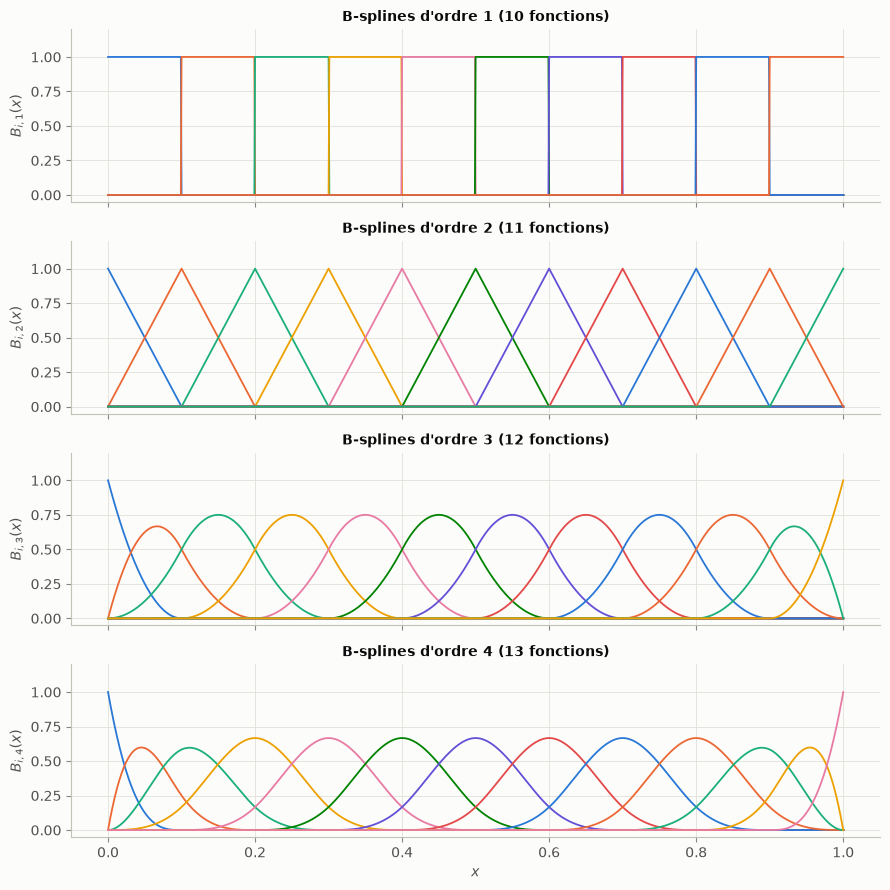

In [8]:
inner = np.arange(0.1, 1.0, 0.1)
t = np.linspace(0, 1, 1001)
fig, axes = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
for m, ax in zip(range(1, 5), axes):
    B = bspline_basis(t, inner, 0.0, 1.0, order=m)
    for i in range(B.shape[1]):
        ax.plot(t, B[:, i], lw=1.3, color=COLORS[i % len(COLORS)])
    ax.set_ylim(-0.05, 1.2)
    ax.set_ylabel("$B_{i,%d}(x)$" % m)
    ax.set_title("B-splines d'ordre %d (%d fonctions)" % (m, B.shape[1]), fontsize=10)
axes[-1].set_xlabel("$x$")
plt.tight_layout()
plt.show()

Vérifions la partition de l'unité et le fait que B-splines et puissances tronquées
engendrent **le même espace** (la projection de l'une sur l'autre est exacte).

In [9]:
B4 = bspline_basis(t, inner, 0.0, 1.0, order=4)
T4 = truncated_power_basis(t, inner, degree=3)
coef, *_ = np.linalg.lstsq(T4, B4, rcond=None)
print("max |somme des B-splines - 1| :", np.abs(B4.sum(1) - 1).max())
print("dimensions :", B4.shape[1], T4.shape[1])
print("résidu de projection B -> puissances tronquées :", np.abs(T4 @ coef - B4).max())

max |somme des B-splines - 1| : 4.440892098500626e-16
dimensions : 13 13
résidu de projection B -> puissances tronquées : 7.120391218763663e-13


**Conditionnement.** Comparons le conditionnement $\kappa(\mathbf H) = \sigma_{\max} /
\sigma_{\min}$ des deux matrices de régression quand le nombre de nœuds augmente (avec
$x \in [0, 10]$). Plus $\kappa$ est grand, plus la résolution des équations normales perd
de chiffres significatifs.

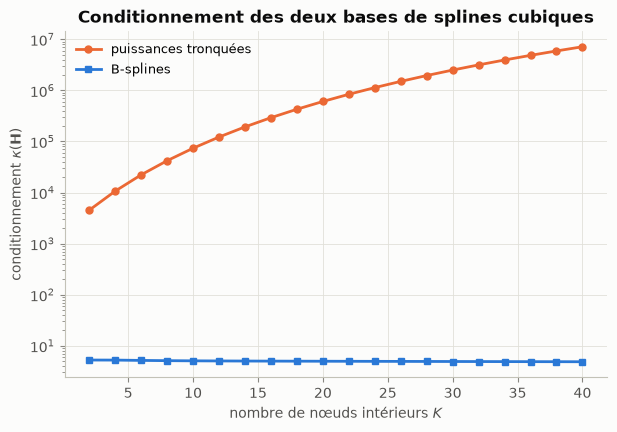

In [10]:
xx = np.linspace(0, 10, 500)
Ks = np.arange(2, 41, 2)
cond_tp, cond_bs = [], []
for K in Ks:
    kn = np.linspace(0, 10, K + 2)[1:-1]
    cond_tp.append(np.linalg.cond(truncated_power_basis(xx, kn)))
    cond_bs.append(np.linalg.cond(bspline_basis(xx, kn, 0, 10)))
plt.figure(figsize=(7, 4.5))
plt.semilogy(Ks, cond_tp, "o-", color=ORANGE, label="puissances tronquées")
plt.semilogy(Ks, cond_bs, "s-", color=BLUE, label="B-splines")
plt.xlabel("nombre de nœuds intérieurs $K$")
plt.ylabel(r"conditionnement $\kappa(\mathbf{H})$")
plt.title("Conditionnement des deux bases de splines cubiques")
plt.legend()
plt.show()

> **À retenir.** Les deux bases engendrent le même espace (mêmes ajustements en
> arithmétique exacte), mais la base des B-splines est bien conditionnée et creuse
> (chaque ligne de $\mathbf H$ a au plus $M$ valeurs non nulles), d'où des calculs en
> $O(N)$ quand les données sont triées.

## 5. Splines cubiques naturelles

Les polynômes ajustés ont un comportement erratique près des bords, et extrapoler est
dangereux. Les splines aggravent ce phénomène. Une **spline cubique naturelle** impose en
plus que la fonction soit **linéaire au-delà des nœuds de bord** : $f'' = f''' = 0$ à
gauche de $\xi_1$ et à droite de $\xi_K$. Cela libère $2 \times 2 = 4$ degrés de liberté,
que l'on peut réinvestir en ajoutant des nœuds à l'intérieur.

Une spline cubique naturelle à $K$ nœuds se représente par $K$ fonctions de base
(éq. (5.4)-(5.5), exercice 5.4) :

$$
N_1(X) = 1,\quad N_2(X) = X,\quad N_{k+2}(X) = d_k(X) - d_{K-1}(X),\qquad
d_k(X) = \frac{(X - \xi_k)_+^3 - (X-\xi_K)_+^3}{\xi_K - \xi_k}.
$$

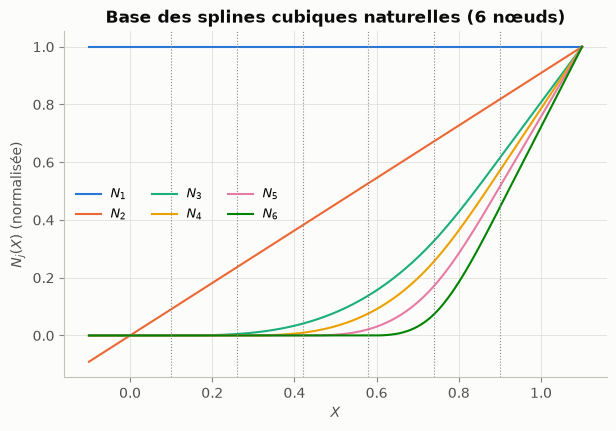

In [11]:
xi_nat = np.linspace(0.1, 0.9, 6)
tt = np.linspace(-0.1, 1.1, 600)
Nb = natural_spline_basis(tt, xi_nat)
plt.figure(figsize=(7, 4.5))
for j in range(Nb.shape[1]):
    plt.plot(tt, Nb[:, j] / np.abs(Nb[:, j]).max(), color=COLORS[j], lw=1.5,
             label="$N_{%d}$" % (j + 1))
for k in xi_nat:
    plt.axvline(k, color=GRAY, lw=0.8, ls=":")
plt.xlabel("$X$")
plt.ylabel("$N_j(X)$ (normalisée)")
plt.title("Base des splines cubiques naturelles (6 nœuds)")
plt.legend(ncol=3)
plt.show()

On voit que chaque $N_j$ devient **affine** à droite de $\xi_K = 0{,}9$ (et à gauche de
$\xi_1$, où les puissances tronquées sont nulles).

### Variance ponctuelle (figure 5.3)

Pour un ajustement par moindres carrés $\hat f(x_0) = h(x_0)^T\hat\beta$ avec
$\hat\beta = (\mathbf H^T\mathbf H)^{-1}\mathbf H^T\mathbf y$ et
$\mathrm{Var}(\mathbf y) = \sigma^2 \mathbf I$, on a
$\mathrm{Var}(\hat\beta) = (\mathbf H^T\mathbf H)^{-1}\mathbf H^T(\sigma^2\mathbf I)
\mathbf H(\mathbf H^T\mathbf H)^{-1} = \sigma^2(\mathbf H^T\mathbf H)^{-1}$, donc

$$
\mathrm{Var}\,\hat f(x_0) = \sigma^2\, h(x_0)^T(\mathbf H^T\mathbf H)^{-1}h(x_0).
$$

On compare quatre modèles sur $N = 50$ points uniformes sur $[0, 1]$ avec $\sigma^2 = 1$ :
droite (2 ddl), polynôme cubique (4 ddl), spline cubique à 2 nœuds en 0,33 et 0,66
(6 ddl), spline naturelle à 6 nœuds (bords 0,1 et 0,9, 4 nœuds intérieurs équirépartis,
6 ddl).

In [ ]:
rng = np.random.RandomState(0)
x50 = np.sort(rng.uniform(0, 1, 50))
bases = {
    "Linéaire globale": lambda t: np.column_stack([np.ones_like(t), t]),
    "Polynôme cubique global": lambda t: np.vander(t, 4, increasing=True),
    "Spline cubique - 2 nœuds": lambda t: bspline_basis(t, [0.33, 0.66], 0, 1),
    "Spline naturelle - 6 nœuds": lambda t: natural_spline_basis(t, np.linspace(0.1, 0.9, 6)),
}

def variance_ponctuelle(Hfun, xtrain, x0, sigma2=1.0):
    H = Hfun(xtrain)
    G = np.linalg.inv(H.T @ H)
    h0 = Hfun(x0)
    return sigma2 * np.einsum("ij,jk,ik->i", h0, G, h0)

plt.figure(figsize=(7, 4.5))
for c, (nom, Hf) in zip(COLORS, bases.items()):
    plt.plot(x50, variance_ponctuelle(Hf, x50, x50), "o-", ms=3, lw=1.2, color=c,
             label="%s (%d ddl)" % (nom, Hf(x50).shape[1]))
plt.xlabel("$X$")
plt.ylabel(r"$\mathrm{Var}\,\hat f(x)$")
plt.title("Variances ponctuelles de quatre modèles (figure 5.3)")
plt.legend()
plt.show()

> **À retenir.** La variance « explose » près des bords, et c'est pire pour la spline
> cubique (libre au-delà des nœuds de bord). La spline naturelle, à degrés de liberté
> égaux, a une variance bien plus faible aux bords - au prix d'un biais éventuel si la
> vraie fonction n'y est pas linéaire, hypothèse souvent raisonnable là où l'on dispose de
> peu d'information. La bosse de la spline naturelle vers $x \approx 0{,}25$ provient
> d'un « trou » dans cet échantillon de 50 points : peu de données près d'un nœud
> intérieur. Notons au passage que $\sum_i \mathrm{Var}\hat f(x_i)/\sigma^2 =
> \mathrm{tr}(\mathbf H(\mathbf H^T\mathbf H)^{-1}\mathbf H^T) = M$ (nombre de ddl).

In [ ]:
for nom, Hf in bases.items():
    print("%-28s somme des variances = %.3f" % (nom, variance_ponctuelle(Hf, x50, x50).sum()))